=== ETAPA 1: DIMENSIONES INICIALES ===
Filas: 10999 | Columnas: 12

Tipos de variables:
ID                      int64
Warehouse_block        object
Mode_of_Shipment       object
Customer_care_calls     int64
Customer_rating         int64
Cost_of_the_Product     int64
Prior_purchases         int64
Product_importance     object
Gender                 object
Discount_offered        int64
Weight_in_gms           int64
Reached.on.Time_Y.N     int64
dtype: object

Valores nulos por columna:
ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64
Filas duplicadas exactas: 0

Distribución inicial de variables categóricas:

-- Warehouse_block --
Warehouse_block
F    3666
D    1834
A    1833
B    1833
C    1833
Name: count, dtype: int64

-- Mo

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Estado_Entrega
0,1,D,Flight,4,2,177,3,low,F,44,1233,1,A tiempo
1,2,F,Flight,4,5,216,2,low,M,59,3088,1,A tiempo
2,3,A,Flight,2,2,183,4,low,M,48,3374,1,A tiempo
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1,A tiempo
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1,A tiempo
5,6,F,Flight,3,1,162,3,medium,F,12,1417,1,A tiempo
6,7,D,Flight,3,4,250,3,low,F,3,2371,1,A tiempo
7,8,F,Flight,4,1,233,2,low,F,48,2804,1,A tiempo
8,9,A,Flight,3,4,150,3,low,F,11,1861,1,A tiempo
9,10,B,Flight,3,2,164,3,medium,F,29,1187,1,A tiempo



=== ETAPA 2: TENDENCIA CENTRAL Y DISPERSIÓN ===


,Variable,Media,Mediana,Moda,Rango,Varianza,Desv_Estandar,IQR,Outliers_IQR
0,Weight_in_gms,3634.02,4149.0,4883,6845,2674458.75,1635.38,3210.5,0
1,Cost_of_the_Product,210.20,214.0,245,214,2310.08,48.06,82.0,0
2,Discount_offered,13.37,7.0,10,64,262.62,16.21,6.0,2209
3,Customer_care_calls,4.05,4.0,4,5,1.30,1.14,2.0,0
4,Customer_rating,2.99,3.0,3,4,2.00,1.41,2.0,0
5,Prior_purchases,3.57,3.0,3,8,2.32,1.52,1.0,1003



=== COMPARACIÓN POR ESTADO DE ENTREGA (PROMEDIOS) ===


,Weight_in_gms,Cost_of_the_Product,Discount_offered,Customer_care_calls,Customer_rating,Prior_purchases
Estado_Entrega,,,,,,
A tiempo,3272.64,207.29,18.66,3.99,3.01,3.50
No a tiempo,4168.67,214.50,5.55,4.15,2.97,3.67



=== COMPARACIÓN POR ESTADO DE ENTREGA (MEDIANAS) ===


,Weight_in_gms,Cost_of_the_Product,Discount_offered,Customer_care_calls,Customer_rating,Prior_purchases
Estado_Entrega,,,,,,
A tiempo,3231.0,209.0,9.0,4.0,3.0,3.0
No a tiempo,4674.0,222.0,6.0,4.0,3.0,3.0



=== CORRELACIONES PRINCIPALES ===


,Discount_offered,Reached.on.Time_Y.N
Weight_in_gms,-0.376,-0.269
Cost_of_the_Product,-0.138,-0.074
Discount_offered,1.000,0.397
Customer_care_calls,-0.131,-0.067
Customer_rating,-0.003,0.013
Prior_purchases,-0.083,-0.056
Reached.on.Time_Y.N,0.397,1.000


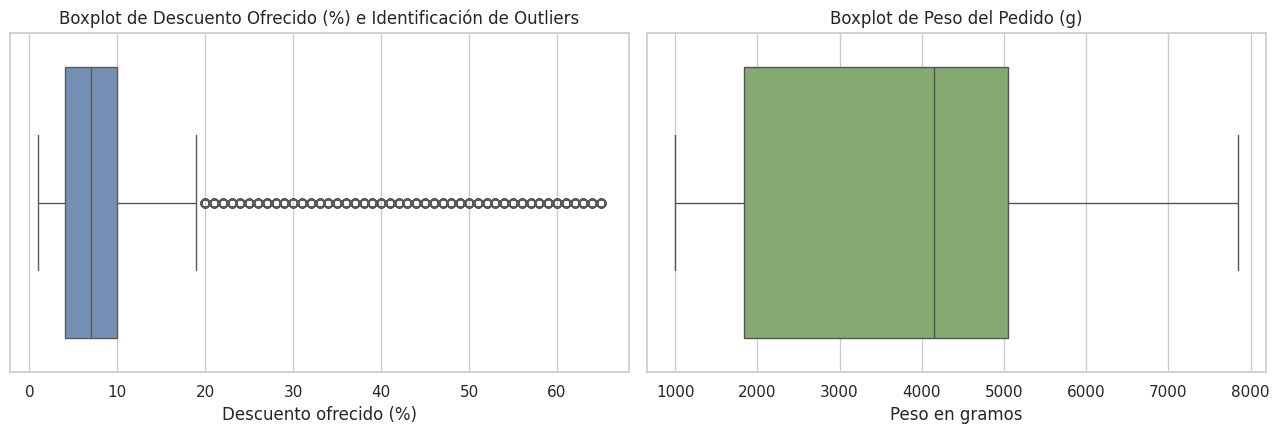

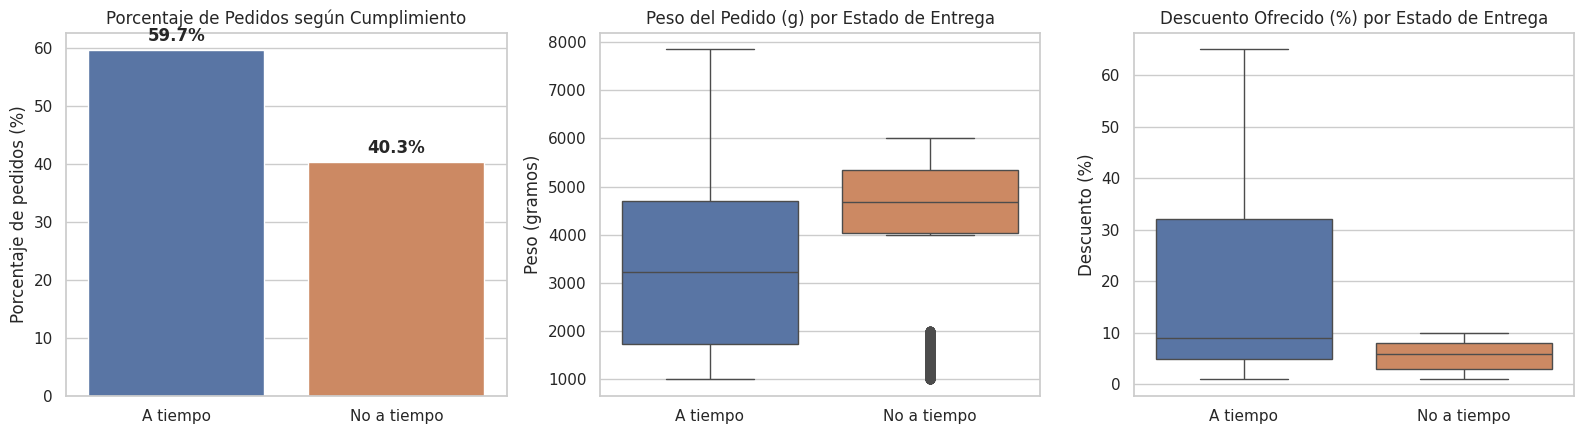


=== ETAPA 3: MODELO PREDICTIVO SIMPLE (REGRESIÓN LINEAL) ===
Ecuación: y_hat = 26.8745 + (-0.003721 * Weight_in_gms)
R² en prueba:   0.1467 (14.67%)
MAE en prueba:  10.23
RMSE en prueba: 14.78


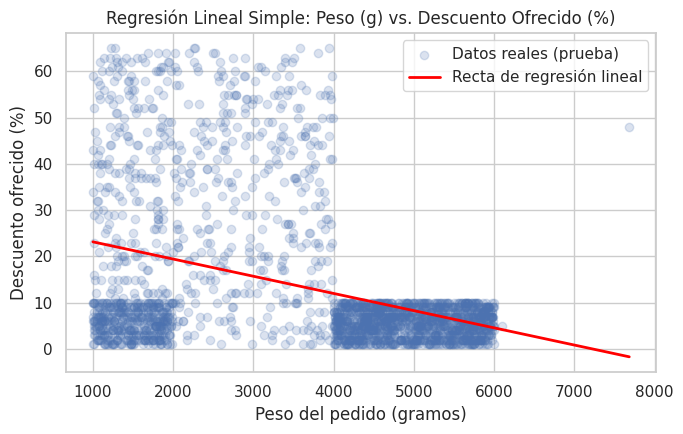


=== CONTRASTE CON REGRESIÓN LINEAL MÚLTIPLE ===
R² en prueba:   0.2916 (29.16%)
MAE en prueba:  9.81
RMSE en prueba: 13.46

=== STORYTELLING Y APLICACIÓN PROFESIONAL ===

STORYTELLING — LOGIPREDICT (10,999 PEDIDOS ONLINE)
- Cumplimiento de entrega: El 59.67% de los pedidos llega a tiempo y el 40.33% no llega a tiempo,
  mostrando un margen importante para prevenir retrasos y fricciones operativas.
- Contraste por peso y descuentos: Los pedidos que no llegan a tiempo tienen mayor peso promedio
  (4,168.67 g vs. 3,272.64 g en entregas a tiempo) y menor descuento promedio (5.55% vs. 18.66%).
- Hallazgo del modelo: La regresión lineal simple (peso -> descuento) logra un R² de 0.1467 y MAE de 10.23
  en prueba, mientras que la regresión lineal múltiple sube el R² a 0.2916 y baja el MAE a 9.81,
  evidenciando que las variables operativas aportan información pero existen relaciones no lineales.

APLICACIÓN PROFESIONAL EN INGENIERÍA DE SISTEMAS:
- Automatizar pipelines de limpieza, validación

In [6]:
# --------------------------------------------------------------------------
# PROYECTO LOGIPREDICT: ANÁLISIS DE PEDIDOS ONLINE Y LOGÍSTICA (Train.csv)
# Danna Valentina Martínez Pineda - Juana Manuela Loaiza López
# --------------------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")


# --------------------------------------------------------------------------
# ETAPA 1 · EXPLORACIÓN Y PREPARACIÓN DE DATOS
# --------------------------------------------------------------------------

url_dataset = "https://raw.githubusercontent.com/valenthiina0606-cell/Logipredict-pedidos-online/refs/heads/main/datos/Train.csv"
df = pd.read_csv(url_dataset)

print("=== ETAPA 1: DIMENSIONES INICIALES ===")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print("\nTipos de variables:")
print(df.dtypes)

print("\nValores nulos por columna:")
print(df.isnull().sum())
print("Filas duplicadas exactas:", int(df.duplicated().sum()))

print("\nDistribución inicial de variables categóricas:")
for col in ["Warehouse_block", "Mode_of_Shipment", "Product_importance", "Gender", "Reached.on.Time_Y.N"]:
    print(f"\n-- {col} --")
    print(df[col].value_counts(dropna=False))

# Limpieza y transformación
df_clean = df.drop_duplicates().copy()

for col in df_clean.select_dtypes(include=[np.number]).columns:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include=["object"]).columns:
    if df_clean[col].isnull().sum() > 0 and not df_clean[col].mode().empty:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

df_clean["Estado_Entrega"] = np.where(
    df_clean["Reached.on.Time_Y.N"] == 1, "A tiempo", "No a tiempo"
)

print("\n=== RESUMEN DEL DATASET DEPURADO ===")
print(f"Registros finales: {len(df_clean)} | Columnas: {df_clean.shape[1]}")
print("Nulos restantes:", int(df_clean.isnull().sum().sum()))
display(df_clean.head(10))


# --------------------------------------------------------------------------
# ETAPA 2 · ESTADÍSTICA DESCRIPTIVA Y PREPROCESAMIENTO
# --------------------------------------------------------------------------

vars_num = [
    "Weight_in_gms",
    "Cost_of_the_Product",
    "Discount_offered",
    "Customer_care_calls",
    "Customer_rating",
    "Prior_purchases",
]

resumen_stats = []
for col in vars_num:
    s = df_clean[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    outliers_count = int(((s < lim_inf) | (s > lim_sup)).sum())

    resumen_stats.append({
        "Variable": col,
        "Media": round(s.mean(), 2),
        "Mediana": round(s.median(), 2),
        "Moda": round(s.mode()[0], 2),
        "Rango": round(s.max() - s.min(), 2),
        "Varianza": round(s.var(), 2),
        "Desv_Estandar": round(s.std(), 2),
        "IQR": round(iqr, 2),
        "Outliers_IQR": outliers_count,
    })

df_stats = pd.DataFrame(resumen_stats)
print("\n=== ETAPA 2: TENDENCIA CENTRAL Y DISPERSIÓN ===")
display(df_stats)

print("\n=== COMPARACIÓN POR ESTADO DE ENTREGA (PROMEDIOS) ===")
display(df_clean.groupby("Estado_Entrega")[vars_num].mean().round(2))

print("\n=== COMPARACIÓN POR ESTADO DE ENTREGA (MEDIANAS) ===")
display(df_clean.groupby("Estado_Entrega")[vars_num].median().round(2))

print("\n=== CORRELACIONES PRINCIPALES ===")
corr = df_clean[vars_num + ["Reached.on.Time_Y.N"]].corr()
display(corr[["Discount_offered", "Reached.on.Time_Y.N"]].round(3))

# Gráficos de naturaleza de datos

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df_clean, x="Discount_offered", ax=axes[0], color="#6C8EBF")
axes[0].set_title("Boxplot de Descuento Ofrecido (%) e Identificación de Outliers")
axes[0].set_xlabel("Descuento ofrecido (%)")

sns.boxplot(data=df_clean, x="Weight_in_gms", ax=axes[1], color="#82B366")
axes[1].set_title("Boxplot de Peso del Pedido (g)")
axes[1].set_xlabel("Peso en gramos")
plt.tight_layout()
plt.show()


# --------------------------------------------------------------------------
# ETAPA 3 · VISUALIZACIONES, MODELO PREDICTIVO Y STORYTELLING
# --------------------------------------------------------------------------

# Visualizaciones finales para storytelling

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

tasas = df_clean["Estado_Entrega"].value_counts(normalize=True) * 100
sns.barplot(
    x=tasas.index,
    y=tasas.values,
    hue=tasas.index,
    legend=False,
    ax=axes[0],
    palette=["#4C72B0", "#DD8452"],
)
axes[0].set_title("Porcentaje de Pedidos según Cumplimiento")
axes[0].set_ylabel("Porcentaje de pedidos (%)")
axes[0].set_xlabel("")
for i, v in enumerate(tasas.values):
    axes[0].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold")

sns.boxplot(
    data=df_clean,
    x="Estado_Entrega",
    y="Weight_in_gms",
    hue="Estado_Entrega",
    legend=False,
    ax=axes[1],
    palette=["#4C72B0", "#DD8452"],
)
axes[1].set_title("Peso del Pedido (g) por Estado de Entrega")
axes[1].set_xlabel("")
axes[1].set_ylabel("Peso (gramos)")

sns.boxplot(
    data=df_clean,
    x="Estado_Entrega",
    y="Discount_offered",
    hue="Estado_Entrega",
    legend=False,
    ax=axes[2],
    palette=["#4C72B0", "#DD8452"],
)
axes[2].set_title("Descuento Ofrecido (%) por Estado de Entrega")
axes[2].set_xlabel("")
axes[2].set_ylabel("Descuento (%)")

plt.tight_layout()
plt.show()

# 2. Modelo predictivo simple: Regresión Lineal Simple (Weight_in_gms -> Discount_offered)
X_simple = df_clean[["Weight_in_gms"]]
y = df_clean["Discount_offered"]

X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

modelo_simple = LinearRegression()
modelo_simple.fit(X_train_s, y_train)
y_pred_s = modelo_simple.predict(X_test_s)

r2_s = r2_score(y_test, y_pred_s)
mae_s = mean_absolute_error(y_test, y_pred_s)
rmse_s = np.sqrt(mean_squared_error(y_test, y_pred_s))

print("\n=== ETAPA 3: MODELO PREDICTIVO SIMPLE (REGRESIÓN LINEAL) ===")
print(f"Ecuación: y_hat = {modelo_simple.intercept_:.4f} + ({modelo_simple.coef_[0]:.6f} * Weight_in_gms)")
print(f"R² en prueba:   {r2_s:.4f} ({r2_s*100:.2f}%)")
print(f"MAE en prueba:  {mae_s:.2f}")
print(f"RMSE en prueba: {rmse_s:.2f}")

plt.figure(figsize=(7, 4.5))
plt.scatter(X_test_s["Weight_in_gms"], y_test, alpha=0.2, label="Datos reales (prueba)")
orden = np.argsort(X_test_s["Weight_in_gms"].values)
plt.plot(
    X_test_s["Weight_in_gms"].values[orden],
    y_pred_s[orden],
    color="red",
    linewidth=2,
    label="Recta de regresión lineal",
)
plt.title("Regresión Lineal Simple: Peso (g) vs. Descuento Ofrecido (%)")
plt.xlabel("Peso del pedido (gramos)")
plt.ylabel("Descuento ofrecido (%)")
plt.legend()
plt.tight_layout()
plt.show()

# Contraste con Regresión Lineal Múltiple
cols_multi = [
    "Weight_in_gms",
    "Cost_of_the_Product",
    "Customer_care_calls",
    "Customer_rating",
    "Prior_purchases",
    "Reached.on.Time_Y.N",
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
]
X_multi = pd.get_dummies(df_clean[cols_multi], drop_first=True)
X_train_m, X_test_m, _, _ = train_test_split(X_multi, y, test_size=0.2, random_state=42)

modelo_multi = LinearRegression()
modelo_multi.fit(X_train_m, y_train)
y_pred_m = modelo_multi.predict(X_test_m)

r2_m = r2_score(y_test, y_pred_m)
mae_m = mean_absolute_error(y_test, y_pred_m)
rmse_m = np.sqrt(mean_squared_error(y_test, y_pred_m))

print("\n=== CONTRASTE CON REGRESIÓN LINEAL MÚLTIPLE ===")
print(f"R² en prueba:   {r2_m:.4f} ({r2_m*100:.2f}%)")
print(f"MAE en prueba:  {mae_m:.2f}")
print(f"RMSE en prueba: {rmse_m:.2f}")

# Storytelling y Aplicación Profesional
print("\n=== STORYTELLING Y APLICACIÓN PROFESIONAL ===")
print("""
STORYTELLING — LOGIPREDICT (10,999 PEDIDOS ONLINE)
- Cumplimiento de entrega: El 59.67% de los pedidos llega a tiempo y el 40.33% no llega a tiempo,
  mostrando un margen importante para prevenir retrasos y fricciones operativas.
- Contraste por peso y descuentos: Los pedidos que no llegan a tiempo tienen mayor peso promedio
  (4,168.67 g vs. 3,272.64 g en entregas a tiempo) y menor descuento promedio (5.55% vs. 18.66%).
- Hallazgo del modelo: La regresión lineal simple (peso -> descuento) logra un R² de 0.1467 y MAE de 10.23
  en prueba, mientras que la regresión lineal múltiple sube el R² a 0.2916 y baja el MAE a 9.81,
  evidenciando que las variables operativas aportan información pero existen relaciones no lineales.

APLICACIÓN PROFESIONAL EN INGENIERÍA DE SISTEMAS:
- Automatizar pipelines de limpieza, validación de datos y detección de anomalías antes de alimentar
  sistemas de gestión logística o tableros de control.
- Implementar alertas tempranas y priorización de pedidos con mayor riesgo operativo (por ejemplo,
  paquetes pesados o flujos con menor cumplimiento).

APLICACIÓN PROFESIONAL EN INGENIERÍA QUÍMICA:
- Aplicar el análisis de dispersión, desviación estándar y valores atípicos (outliers) al monitoreo
  de variables de proceso, control de calidad y detección de condiciones fuera de control.
- Optimizar el manejo, almacenamiento y transporte de materias primas, insumos y producto terminado
  considerando peso, costos y tiempos de respuesta.
""")